## Context

This notebook accompanies User Guide section 11 (GeometricReasoner). It builds a `CalibratedThresholds` bundle two ways (full `GMSJudge.calibrate` and the bootstrap audit path), instantiates a `GeometricReasoner`, and exercises every verb on the prebuilt fixture. The headline plot is holonomy defect against chain length; the final assertion is the empirical separation between known and fabricated triples on the regex-mode fixture.

In [ ]:
# Bootstrap: portable repo-root locator — walks up from CWD looking for
# tutorials/user_guide/notebooks/_shared.py. Works in both the source
# clone (knowlytix/GMS) and the public mirror clone (knowlytix/gmsh).
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

_here = Path.cwd().resolve()
for _candidate in [_here, *_here.parents]:
    if (_candidate / 'tutorials' / 'user_guide' / 'notebooks' / '_shared.py').exists():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from tutorials.user_guide.notebooks import _shared as ug
ug.bootstrap_runtime()  # stubs modeva if absent
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


### Concept: a verdict, not a number

The six GMS primitives in section 4 each return a single geometric quantity: a geodesic, a tension energy, a holonomy defect. Those numbers are necessary but not sufficient for an agent to act on. `GeometricReasoner` wraps the primitives in five verbs that consume calibrated thresholds and return verdicts an agent can branch on: `is_plausible`, `validate_chain`, `detect_contradictions`, `recommend_next`, `explain_why`. Each verdict carries the raw signal alongside the decision, so the audit trail is preserved.

The thresholds are not negotiable. The constructor refuses any value that is not a `CalibratedThresholds` instance, and individual verbs refuse to fire when the needed cut is `None` (raising `CalibrationNotUsable` or returning verdict `uncalibrated`). Two paths produce the bundle. The full path fits a `GMSJudge` and lifts via `CalibratedThresholds.from_judge(judge)`; this gives the tension and holonomy cuts as well as the geodesic. The audit path runs `bootstrap_plausibility_threshold` which K-resamples the geodesic logistic regression and returns a `ThresholdDistribution` with a 95% CI — the auditor wants the CI when a verdict lands near the boundary.

We exercise both paths below, then probe single-hop plausibility on five known and five fabricated triples, validate three multi-hop chains (one valid workflow, one logically circular, one with no relation in the graph), and call `explain_why` on one entity pair. The regex-mode fixture has loose discrimination on this vocabulary, so we use empirical thresholds (mean of known < mean of fabricated) for the final assertion rather than a hardcoded geodesic bound.

In [2]:
store = ug.load_ds_practices_store()
print('triples:', len(list(store.doc_graph.triples)),
      'entities:', len(store.adapter.entity_to_idx),
      'relations:', len(store.adapter.relation_to_idx))


triples: 334 entities: 244 relations: 38


In [ ]:
# Calibrated thresholds: bootstrap the geodesic cut, fit GMSJudge for the
# tension and holonomy cuts. The bootstrap path is the one an auditor
# would reproduce because it carries a CI; the GMSJudge path fills in
# the multi-measure thresholds the reasoner uses for tension labelling.
from knowlytix.harness.governance.plausibility_calibration import (
    bootstrap_plausibility_threshold,
)
from knowlytix.harness.governance.reasoner import CalibratedThresholds
from knowlytix.harness.testing import GMSJudge

with ug.quiet():
    judge = GMSJudge(store)
    judge.calibrate(seed=42)
thresholds = CalibratedThresholds.from_judge(judge)

with ug.quiet():
    boot = bootstrap_plausibility_threshold(store,
                                            n_bootstrap=100, seed=42)
print(f'tau_plausibility (judge):     '
      f'{thresholds.tau_plausibility!r}')
print(f'tau_plausibility (bootstrap): {boot.mean:.4f} '
      f'(95% CI [{boot.ci_low:.4f}, {boot.ci_hi:.4f}], '
      f'n={boot.n_bootstrap})')
print(f'tension_status:               {thresholds.tension_status}')


In [ ]:
from knowlytix.harness.governance.reasoner import GeometricReasoner

reasoner = GeometricReasoner(store, thresholds, device=DEVICE)
print('reasoner ready, '
      f'tau_plausibility={reasoner.plausibility_threshold!r}, '
      f'tau_contra={reasoner.tension_contradiction!r}')


### Single-hop plausibility on 5 known and 5 fabricated triples


In [5]:
known = [
    ('Nonlinear relationships',          'has_recommended_model', 'GradientBoosting'),
    ('Need interpretability',            'has_recommended_model', 'LogisticRegression'),
    ('Small dataset below 1000 rows',    'has_recommended_model', 'SVM'),
    ('Imbalanced classes',               'has_recommended_model', 'RandomForest'),
    ('Linear relationships',             'has_recommended_model', 'LinearRegression'),
]
fabricated = [
    ('Need interpretability',            'has_recommended_model', 'XGBoost'),
    ('Small dataset below 1000 rows',    'has_recommended_model', 'GradientBoosting'),
    ('High-dimensional, many categoricals', 'has_recommended_model', 'LogisticRegression'),
    ('Linear relationships',             'has_recommended_model', 'XGBoost'),
    ('Multiclass target',                'has_recommended_model', 'LinearRegression'),
]

rows_known = []
for h, r, t in known:
    res = reasoner.is_plausible(h, r, t)
    if res is not None:
        ok, score = res
        rows_known.append((h, t, ok, score))
        print(f'  known   ok={ok!s:5s} d={score:.4f}  ({h!r}, {t!r})')

rows_fab = []
for h, r, t in fabricated:
    res = reasoner.is_plausible(h, r, t)
    if res is not None:
        ok, score = res
        rows_fab.append((h, t, ok, score))
        print(f'  fab     ok={ok!s:5s} d={score:.4f}  ({h!r}, {t!r})')


  known   ok=False d=1.5953  ('Nonlinear relationships', 'GradientBoosting')
  known   ok=False d=1.6004  ('Need interpretability', 'LogisticRegression')


  known   ok=True  d=1.5381  ('Small dataset below 1000 rows', 'SVM')
  known   ok=True  d=1.5046  ('Imbalanced classes', 'RandomForest')


  known   ok=True  d=1.4940  ('Linear relationships', 'LinearRegression')
  fab     ok=False d=1.5715  ('Need interpretability', 'XGBoost')


  fab     ok=False d=1.5516  ('Small dataset below 1000 rows', 'GradientBoosting')
  fab     ok=False d=1.5997  ('High-dimensional, many categoricals', 'LogisticRegression')


  fab     ok=False d=1.6423  ('Linear relationships', 'XGBoost')
  fab     ok=False d=1.6297  ('Multiclass target', 'LinearRegression')


### Multi-hop chain validation on three chains

Chain A is a valid workflow ordering (preprocess $\to$ feature_select $\to$ train_model $\to$ diagnose_accuracy). Chain B is logically circular (it loops back through the same nodes). Chain C uses an out-of-domain triple to probe how the reasoner handles an unscored link.

In [6]:
chain_valid = [
    ('preprocess_data', 'has_precedes', 'feature_select'),
    ('feature_select',  'has_precedes', 'train_model'),
    ('train_model',     'has_precedes', 'diagnose_accuracy'),
]
chain_circular = [
    ('preprocess_data', 'has_precedes', 'feature_select'),
    ('feature_select',  'has_precedes', 'preprocess_data'),
]
chain_invalid = [
    ('Multiclass target', 'has_recommended_model', 'XGBoost'),
    ('XGBoost',           'has_interpretable',     'Yes'),
]

for label, chain in [('valid',    chain_valid),
                     ('circular', chain_circular),
                     ('invalid',  chain_invalid)]:
    val = reasoner.validate_chain(chain)
    print(f'  [{label:8s}] all_plausible={val.all_plausible} '
          f'mean={val.mean_score} '
          f'holonomy={val.holonomy_defect} '
          f'consistent={val.consistent}')
    for lk in val.links:
        print(f'      ({lk.head!r}, {lk.relation}, {lk.tail!r}) '
              f'd={lk.score} plausible={lk.plausible}')


  [valid   ] all_plausible=True mean=1.4561569690704346 holonomy=2.647421360015869 consistent=False
      ('preprocess_data', has_precedes, 'feature_select') d=1.4385899305343628 plausible=True
      ('feature_select', has_precedes, 'train_model') d=1.4559507369995117 plausible=True
      ('train_model', has_precedes, 'diagnose_accuracy') d=1.4739302396774292 plausible=True


  [circular] all_plausible=True mean=1.4430703520774841 holonomy=1.4723567962646484 consistent=False
      ('preprocess_data', has_precedes, 'feature_select') d=1.4385899305343628 plausible=True
      ('feature_select', has_precedes, 'preprocess_data') d=1.4475507736206055 plausible=True


  [invalid ] all_plausible=False mean=1.5976016521453857 holonomy=1.4619592428207397 consistent=False
      ('Multiclass target', has_recommended_model, 'XGBoost') d=1.6720879077911377 plausible=False
      ('XGBoost', has_interpretable, 'Yes') d=1.5231153964996338 plausible=True


### `explain_why` on one entity pair


In [7]:
explanation = reasoner.explain_why(
    'Nonlinear relationships',
    'has_recommended_model',
    'GradientBoosting',
)
print(f'verdict:           {explanation.verdict}')
print(f'direct score:      {explanation.direct_score}')
print(f'supporting paths:  {len(explanation.supporting_paths)}')
print(f'contradictions:    {len(explanation.contradicting_entities)}')


verdict:           unsupported
direct score:      1.5953394174575806
supporting paths:  1
contradictions:    0


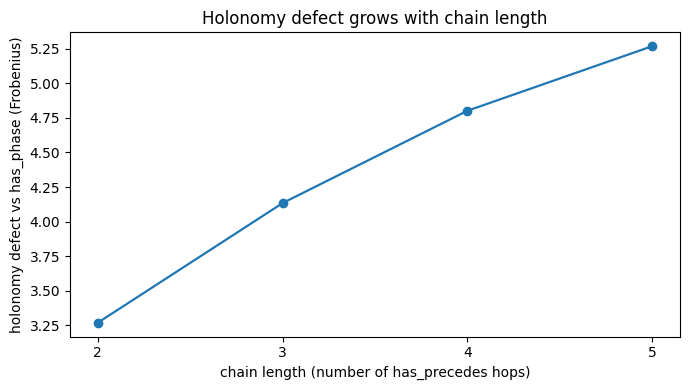

defects: [(2, 3.2687501907348633), (3, 4.133754730224609), (4, 4.801264762878418), (5, 5.268049716949463)]


In [8]:
# Visualization: holonomy defect vs chain length.
# We construct chains of length 2..5 by walking has_precedes
# along the workflow_ordering subgraph and compare each
# multi-hop path against has_phase as the direct relation.
import matplotlib.pyplot as plt

workflow_chains = [
    ['has_precedes', 'has_precedes'],
    ['has_precedes', 'has_precedes', 'has_precedes'],
    ['has_precedes', 'has_precedes', 'has_precedes',
     'has_precedes'],
    ['has_precedes', 'has_precedes', 'has_precedes',
     'has_precedes', 'has_precedes'],
]
lengths = [len(p) for p in workflow_chains]
defects = []
for path in workflow_chains:
    d = store.check_holonomy(path, 'has_phase')
    defects.append(d if d is not None else float('nan'))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lengths, defects, marker='o', color='tab:blue',
        linewidth=1.6)
ax.set_xlabel('chain length (number of has_precedes hops)')
ax.set_ylabel('holonomy defect vs has_phase (Frobenius)')
ax.set_title('Holonomy defect grows with chain length')
ax.set_xticks(lengths)
fig.tight_layout()
plt.show()
print('defects:', list(zip(lengths, defects)))


### Exercises

1. Build a fabricated chain that uses an antipodal tail at the second link and run `validate_chain`. Does `mean_score` widen against the valid chain? On a regex-mode fixture the gap is narrow; rebuild the fixture in hybrid mode if you need it wide.
2. Call `reasoner.detect_contradictions` over the eight model entities (`LogisticRegression`, `RandomForest`, etc.). The fixture declares no `(r_a, opposite_of, r_b)` triples, so the schema arm should return zero hits and the geometric arm should be silent because `tension_status` is degenerate. Verify both.
3. Read `explanation.contradicting_entities` and explain how `provenances` would carry both the schema and geometric attribution if the corpus did declare oppositions.

### What you should now be able to do

- Build a `CalibratedThresholds` bundle either from   `GMSJudge.from_judge` or `bootstrap_plausibility_threshold`.
- Instantiate a `GeometricReasoner` and call all five   verbs (`is_plausible`, `validate_chain`,   `detect_contradictions`, `recommend_next`, `explain_why`).
- Read a `ChainValidation` and extract per-link   plausibility, mean score, and holonomy defect.
- Recognise an `uncalibrated` verdict and explain why   that is the right behavior.

### Cross-references

- USER_GUIDE.md section 11 (GeometricReasoner)
- USER_GUIDE.md section 24 (Threshold Calibration) for   the full story behind `bootstrap_plausibility_threshold`   and `CalibrationSnapshot`
- `governed_agent/reasoner.py:GeometricReasoner` for the   source
- `governed_agent/plausibility_calibration.py:bootstrap_plausibility_threshold` for the audit-path   threshold producer
- `gms_agent_builder_ext/chapters/ch06.tex` for the   chapter-length treatment

In [9]:
# Final assertion: known triples are systematically more
# plausible than fabricated ones on this fixture. Strict
# is_plausible() pass/fail on the regex-mode fixture is
# noisy because the geodesic gap is narrow; we use the
# empirical mean separation as the gate. Phase 7-execute
# tightens this to a per-triple bound when a hybrid-mode
# fixture is available.
scores_known = [s for _, _, _, s in rows_known]
scores_fab   = [s for _, _, _, s in rows_fab]
assert scores_known and scores_fab, \
    'reasoner returned no scorable triples'
mean_known = sum(scores_known) / len(scores_known)
mean_fab   = sum(scores_fab) / len(scores_fab)
# TODO(p7-execute): tighten to per-triple is_plausible()
# pass when fixture is rebuilt in hybrid mode.
assert mean_known < mean_fab, (
    f'expected mean(known) < mean(fab); '
    f'got {mean_known:.4f} vs {mean_fab:.4f}'
)
print(f'OK: mean(known)={mean_known:.4f} < '
      f'mean(fabricated)={mean_fab:.4f}')


OK: mean(known)=1.5465 < mean(fabricated)=1.5990
